# Tarea 2 — Nuestro modelo de Machine Learning

**Introducción a Machine Learning · AST332 · 2026-2**  
**Jaime Bidart · Vanessa Salgado**

## ¿Podemos clasificar la profundidad de un terremoto a partir de su ubicación y magnitud?

En la Tarea 1 vimos que los sismos profundos se concentran en ciertas regiones y no se distribuyen de manera uniforme. A partir de eso nos preguntamos si la ubicación de un terremoto, junto con su magnitud, nos puede ayudar a clasificar su profundidad.

En esta tarea entrenamos un árbol de decisión, evaluamos sus resultados y estudiamos dónde comete errores. No buscamos predecir cuándo ocurrirá el próximo terremoto ni calcular su profundidad exacta.


## 1. Definición del problema

Queremos predecir una **categoría de profundidad** a partir de `depth` (en km). Conservamos los límites propuestos en la Tarea 1:

| Categoría | Profundidad |
|:--|:--|
| **Superficial** | `0 ≤ depth < 70 km` |
| **Intermedia** | `70 ≤ depth ≤ 300 km` |
| **Profunda** | `depth > 300 km` |

Es una clasificación multiclase, el modelo debe elegir una de tres categorías, no predecir una profundidad numérica.

Usaremos `latitude`, `longitude` y `mag` como features. Esperamos que las coordenadas sean útiles porque, como observamos en el EDA, las distintas profundidades presentan patrones geográficos. Incluimos la magnitud para ver cuánto la aprovecha el árbol, aunque no sabemos de antemano si ayudará a separar las clases.

No incluimos `depth` como entrada porque es la varaible a predecir, utilizarla sería data leakage. Tampoco usamos `place`, ya que describe la ubicación ya representada por las coordenadas. Decidimos dejar fuera `magType` al no mantenerse constante y cambiar la forma de medición en el tiempo. Por último usamos la fecha solamente para seleccionar el período de estudio.

Como modelo elegimos un árbol de decisión porque sus reglas se pueden interpretar, permite dividir el mapa en distintas regiones y no necesita estandarizar las variables. Además, podemos modificar su profundidad máxima (`max_depth`) para estudiar cómo influye la complejidad del modelo.


## 2. Datos

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import BallTree
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.grid': True, 'grid.alpha': 0.20,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10,
    'figure.dpi': 110
})
CLASES = ['Superficial', 'Intermedia', 'Profunda']
COLOR = {'Superficial': '#3f7f4f',   # verde árbol
         'Intermedia':  '#a3324a',   # burdeo
         'Profunda':    '#7a5aa8'}   # morado
COLOR_TRAIN, COLOR_TEST = '#3f7f4f', '#7a5aa8'
SEED = 42

# Busca el CSV con el nombre corto o con el nombre largo de Moodle
carpetas = [Path('.'), Path('/content'), Path('/mnt/user-data/uploads'), Path('/mnt/data')]
rutas = [p for c in carpetas for patron in ('earthquakes_usgs*.csv', 'earthquakes.csv')
         for p in sorted(c.glob(patron))]
if not rutas:
    raise FileNotFoundError('Sube el CSV de terremotos al entorno del notebook y ejecuta nuevamente.')
crudo = pd.read_csv(rutas[0])
print(f'CSV utilizado: {rutas[0].name}')
print(f'Catálogo original: {len(crudo):,} filas, {crudo.shape[1]} columnas')

CSV utilizado: earthquakes_usgs_1ecd0e8da06f9a432e2719fd3f2e5df0(1).csv
Catálogo original: 310,535 filas, 13 columnas


Trabajamos con los terremotos de M ≥ 4,5 entre 1980 y 2025, para mantener el mismo enfoque de la Tarea 1. No incluimos 2026 porque está incompleto en el catálogo. Quitamos duplicados, registros que no corresponden a terremotos, filas con datos necesarios faltantes y profundidades negativas. Las profundidades de 0 km se mantienen dentro de la categoría superficial.

Son filtros que definimos de forma previa, no parámetros que el modelo aprenda de los datos. Por eso podemos aplicarlos antes de separar entrenamiento y test sin producir data leakage.


Terremotos M ≥ 4,5 entre 1980 y 2025: 263,489
  con algún faltante: 0   con profundidad negativa: 127
Eventos para el modelo: 263,362


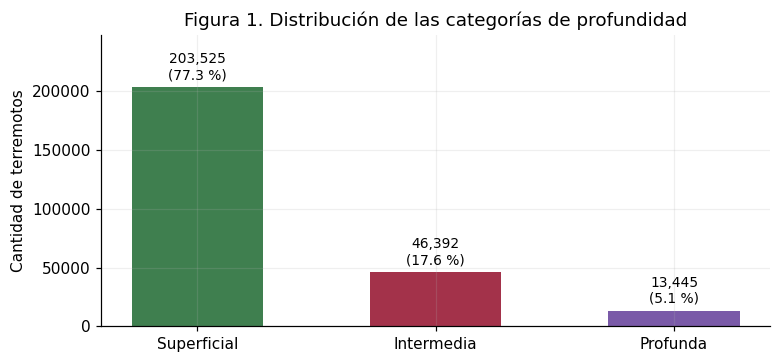

In [ ]:
df = crudo.drop(columns=['Unnamed: 0'], errors='ignore').drop_duplicates().copy()
df['time'] = pd.to_datetime(df['time'], format='mixed', utc=True, errors='coerce')
for col in ['latitude', 'longitude', 'depth', 'mag']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

base = df.loc[df['type'].eq('earthquake')
              & df['time'].dt.year.between(1980, 2025)
              & df['mag'].ge(4.5)].copy()
n_antes = len(base)
n_faltantes = int(base[['depth', 'latitude', 'longitude', 'mag']].isna().any(axis=1).sum())
n_negativas = int(base['depth'].lt(0).sum())

base = base.dropna(subset=['depth', 'latitude', 'longitude', 'mag'])
base = base.loc[base['depth'].ge(0)].copy()
base['clase'] = np.select([base['depth'].lt(70), base['depth'].le(300)],
                          ['Superficial', 'Intermedia'], default='Profunda')

print(f'Terremotos M ≥ 4,5 entre 1980 y 2025: {n_antes:,}')
print(f'  con algún faltante: {n_faltantes:,}   con profundidad negativa: {n_negativas:,}')
print(f'Eventos para el modelo: {len(base):,}')

conteos = base['clase'].value_counts().reindex(CLASES)
fig, ax = plt.subplots(figsize=(7.2, 3.4))
barras = ax.bar(CLASES, conteos.values, color=[COLOR[k] for k in CLASES], width=.55)
ax.bar_label(barras, labels=[f'{n:,}\n({100*n/len(base):.1f} %)' for n in conteos],
             padding=3, fontsize=9)
ax.set(ylabel='Cantidad de terremotos', title='Figura 1. Distribución de las categorías de profundidad',
       ylim=(0, conteos.max() * 1.22))
plt.tight_layout()
plt.show()

La primera observación es que las clases están desbalanceadas. Alrededor del 77% de los eventos son superficiales y solo un 5% son profundos.

Por eso elegimos el F1 macro como métrica principal. Primero combina precision y recall en el F1 de cada clase y luego promedia las tres clases con el mismo peso. También revisaremos accuracy, recall por clase y matrices de confusión para entender mejor los errores.

Hay otra precaución que ya habíamos comentado en la Tarea 1 muchas profundidades aparecen exactamente en 10 o 33 km. Esto puede deberse a que cuando no puede determinarse la profundidad de forma clara se utilizan valores standar. Sin embargo, no podemos concluir que un registro haya sido fijado solo porque tenga uno de esos valores. Revisamos su frecuencia porque podría influir en la interpretación de los errores.


In [ ]:
valores_10_33 = base['depth'].isin([10, 33])
print(f"Eventos con depth = 10 km: {(base['depth'] == 10).sum():,}")
print(f"Eventos con depth = 33 km: {(base['depth'] == 33).sum():,}")
print(f'Fracción de la muestra con profundidad 10 o 33 km: {valores_10_33.mean():.1%}')

Eventos con depth = 10 km: 72,712
Eventos con depth = 33 km: 37,564
Fracción de la muestra con profundidad 10 o 33 km: 41.9%


## 3. Separación entrenamiento / test

Usamos el 80 % de los datos para entrenar y reservamos el 20 % para evaluar. La división es estratificada (`stratify=y`), de modo que las tres categorías mantienen proporciones similares en ambos conjuntos. Fijamos `random_state=42` para que el resultado pueda reproducirse.

El conjunto de test queda reservado para no usarlo para entrenar ni para elegir los parámetros del árbol.


In [ ]:
FEATURES = ['latitude', 'longitude', 'mag']
X = base[FEATURES]
y = base['clase']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

print(f'Entrenamiento: {len(X_train):,} eventos   Test: {len(X_test):,} eventos')
display(pd.DataFrame({
    'Entrenamiento (%)': 100 * y_train.value_counts(normalize=True).reindex(CLASES),
    'Test (%)': 100 * y_test.value_counts(normalize=True).reindex(CLASES)}).round(2))

Entrenamiento: 210,689 eventos   Test: 52,673 eventos


,Entrenamiento (%),Test (%)
clase,,
Superficial,77.28,77.28
Intermedia,17.62,17.62
Profunda,5.11,5.11


## 4. Modelo original: árbol de decisión con `max_depth=8`

Como punto de partida usamos un árbol con profundidad máxima de 8. Elegimos este valor como configuración inicial, sin hacer una búsqueda de hiperparámetros. El criterio de división es Gini, el que utiliza `DecisionTreeClassifier` por defecto.

Evaluamos entrenamiento y test con accuracy y F1-macro, y añadimos una referencia sencilla, usamos un modelo que siempre predice la clase mayoritaria.


In [ ]:
def medir(y_real, y_pred):
    return {'Accuracy': accuracy_score(y_real, y_pred),
            'F1-macro': f1_score(y_real, y_pred, labels=CLASES, average='macro', zero_division=0)}

arbol_base = DecisionTreeClassifier(max_depth=8, random_state=SEED)
arbol_base.fit(X_train, y_train)
pred_train_base = arbol_base.predict(X_train)
pred_test_base = arbol_base.predict(X_test)

pred_trivial = np.full(len(y_test), y_train.value_counts().idxmax())
tabla_base = pd.DataFrame({
    'Árbol max_depth=8 · entrenamiento': medir(y_train, pred_train_base),
    'Árbol max_depth=8 · test': medir(y_test, pred_test_base),
    'Siempre «Superficial» · test': medir(y_test, pred_trivial)}).T
display(tabla_base.round(3))
print(f'Árbol: {arbol_base.get_depth()} niveles, {arbol_base.get_n_leaves()} hojas\n')
print('Métricas por clase (test):')
print(classification_report(y_test, pred_test_base, labels=CLASES, digits=3, zero_division=0))

,Accuracy,F1-macro
Árbol max_depth=8 · entrenamiento,0.838,0.706
Árbol max_depth=8 · test,0.834,0.698
Siempre «Superficial» · test,0.773,0.291


Árbol: 8 niveles, 220 hojas

Métricas por clase (test):
              precision    recall  f1-score   support

 Superficial      0.842     0.969     0.901     40705
  Intermedia      0.672     0.288     0.403      9279
    Profunda      0.974     0.663     0.789      2689

    accuracy                          0.834     52673
   macro avg      0.829     0.640     0.698     52673
weighted avg      0.819     0.834     0.808     52673



**Primera lectura de los resultados.** El árbol alcanza un F1-macro de 0,698 en test, bastante por encima del 0,291 que obtiene predecir siempre superficial. Su accuracy también mejora, pero no tanto, pasa de 77,3 % a 83,4%.

Los resultados en entrenamiento y test son muy parecidos (0,706 y 0,698), así que no vemos una diferencia importante que indique sobreajuste. Sin embargo, el modelo reconoce solo el 28,8% de los sismos intermedios. Esto sugiere que un árbol de ocho niveles podría ser demasiado simple lo que significaria que hay indicios de subajuste.


## 5. Experimento: ¿qué pasa si dejamos crecer el árbol?

Vamos a modificar un solo parámetro: `max_depth=8` pasa a `max_depth=None`. Es decir, el árbol ya no tendrá un límite de profundidad. Mantenemos las mismas variables, la misma semilla y exactamente la misma división entre entrenamiento y test.

### Nuestra predicción, antes de hacer el cambio

Por lo visto en clases, un árbol más profundo tiene mayor capacidad para aprender patrones, pero también mayor riesgo de memorizar ejemplos particulares.

1. En entrenamiento esperamos que el F1-macro se acerque a 1, porque el árbol tendrá libertad para hacer muchas más divisiones.
2. En test creemos que podría mejorar respecto del árbol de ocho niveles, ya que este parece quedarse corto, aunque la mejora no debería ser tan grande como en entrenamiento.
3. La diferencia entre ambos conjuntos esperamos que aumente. Si el árbol aprende demasiados detalles del entrenamiento, aparecerán señales de sobreajuste.


Accuracy  F1-macro
Árbol          Conjunto                         
max_depth=8    Entrenamiento     0.838     0.706
               Test              0.834     0.698
max_depth=None Entrenamiento     1.000     1.000
               Test              0.880     0.835

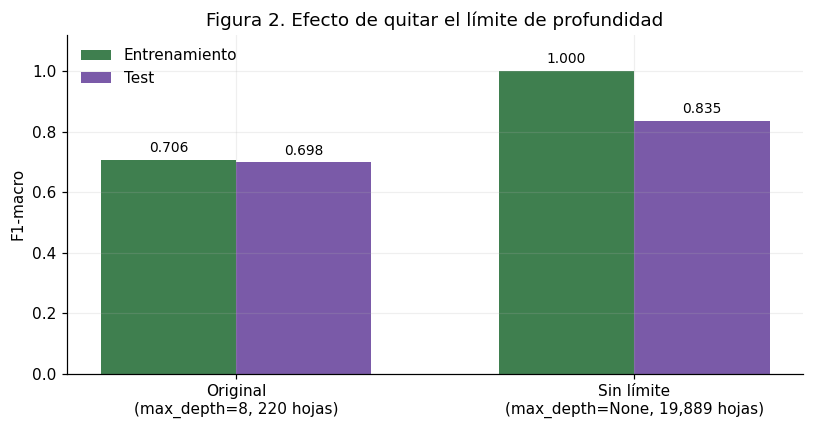

Brecha F1 entrenamiento − test: 0.008 (original) vs 0.165 (sin límite)
Árbol sin límite: 41 niveles, 19,889 hojas

Métricas por clase del árbol sin límite (test):
              precision    recall  f1-score   support

 Superficial      0.924     0.924     0.924     40705
  Intermedia      0.678     0.674     0.676      9279
    Profunda      0.897     0.916     0.906      2689

    accuracy                          0.880     52673
   macro avg      0.833     0.838     0.835     52673
weighted avg      0.879     0.880     0.879     52673



In [ ]:
arbol_libre = DecisionTreeClassifier(max_depth=None, random_state=SEED)
arbol_libre.fit(X_train, y_train)
pred_train_libre = arbol_libre.predict(X_train)
pred_test_libre = arbol_libre.predict(X_test)

m = {('max_depth=8', 'Entrenamiento'): medir(y_train, pred_train_base),
     ('max_depth=8', 'Test'): medir(y_test, pred_test_base),
     ('max_depth=None', 'Entrenamiento'): medir(y_train, pred_train_libre),
     ('max_depth=None', 'Test'): medir(y_test, pred_test_libre)}
comparacion = pd.DataFrame(m).T
comparacion.index.names = ['Árbol', 'Conjunto']
display(comparacion.round(3))

f1 = comparacion['F1-macro'].unstack()[['Entrenamiento', 'Test']].loc[['max_depth=8', 'max_depth=None']]
x, w = np.arange(2), 0.34
fig, ax = plt.subplots(figsize=(7.5, 4))
b1 = ax.bar(x - w/2, f1['Entrenamiento'], w, label='Entrenamiento', color=COLOR_TRAIN)
b2 = ax.bar(x + w/2, f1['Test'], w, label='Test', color=COLOR_TEST)
ax.bar_label(b1, fmt='%.3f', padding=3, fontsize=9)
ax.bar_label(b2, fmt='%.3f', padding=3, fontsize=9)
ax.set(xticks=x, xticklabels=[f'Original\n(max_depth=8, {arbol_base.get_n_leaves()} hojas)',
                               f'Sin límite\n(max_depth=None, {arbol_libre.get_n_leaves():,} hojas)'],
       ylim=(0, 1.12), ylabel='F1-macro', title='Figura 2. Efecto de quitar el límite de profundidad')
ax.legend(loc='upper left', frameon=False)
plt.tight_layout()
plt.show()

brecha = f1['Entrenamiento'] - f1['Test']
print(f"Brecha F1 entrenamiento − test: {brecha['max_depth=8']:.3f} (original) vs {brecha['max_depth=None']:.3f} (sin límite)")
print(f'Árbol sin límite: {arbol_libre.get_depth()} niveles, {arbol_libre.get_n_leaves():,} hojas')
print('\nMétricas por clase del árbol sin límite (test):')
print(classification_report(y_test, pred_test_libre, labels=CLASES, digits=3, zero_division=0))

### Interpretación del experimento

Los resultados van en la dirección que esperábamos. El F1-macro de entrenamiento subió de 0,706 a 1,000 por lo que el árbol sin límite aprendió a clasificar de buena forma los eventos con los que se entrenó. La diferencia entre entrenamiento y test también aumentó, de 0,008 a 0,164, lo que muestra sobreajuste.

Lo interesante es que el resultado de test también mejoró de 0,698 a 0,836. Uno de los cambios más claros aparece en los sismos intermedios, su recall pasó de 28,8% a 67,4%. Esto apoya la idea de que el árbol original tenía una capacidad demasiado limitada para aprender parte de los patrones espaciales.

Así, el árbol sin límite sobreajusta, pero clasifica mejor los eventos de test que el árbol de ocho niveles. El primero memoriza el entrenamiento, pero también aprende patrones útiles que el segundo no alcanzaba a representar.


## 6. Auditoría del modelo

### 6.1 ¿Qué tan bien generaliza?

| Modelo | F1 entrenamiento | F1 test | Diferencia | Interpretación |
|:--|:--:|:--:|:--:|:--|
| `max_depth=8` | 0,706 | 0,698 | 0,008 | Indicios de subajuste: los resultados son parecidos, pero el desempeño sigue siendo limitado, especialmente para la clase intermedia. |
| `max_depth=None` | 1,000 | 0,836 | 0,164 | Sobreajuste: memoriza el entrenamiento, aunque obtiene mejores resultados en test. |

Debemos tener presente que en esta evaluación hicimos una separación aleatoria, y muchos sismos de test están cerca de otros que quedaron en entrenamiento. Más adelante veremos que la distancia mediana al evento de entrenamiento más cercano es de 3,2 km. Por eso, estos resultados muestran principalmente cómo funciona el modelo en regiones representadas en ambos conjuntos, no necesariamente en regiones nuevas.

### 6.2 ¿Dónde falla el modelo?

Primero miramos las matrices de confusión. Cada fila corresponde a la categoría real y cada columna a la predicha. Los porcentajes se calculan dentro de cada fila, así que la diagonal permite leer el recall de cada clase.


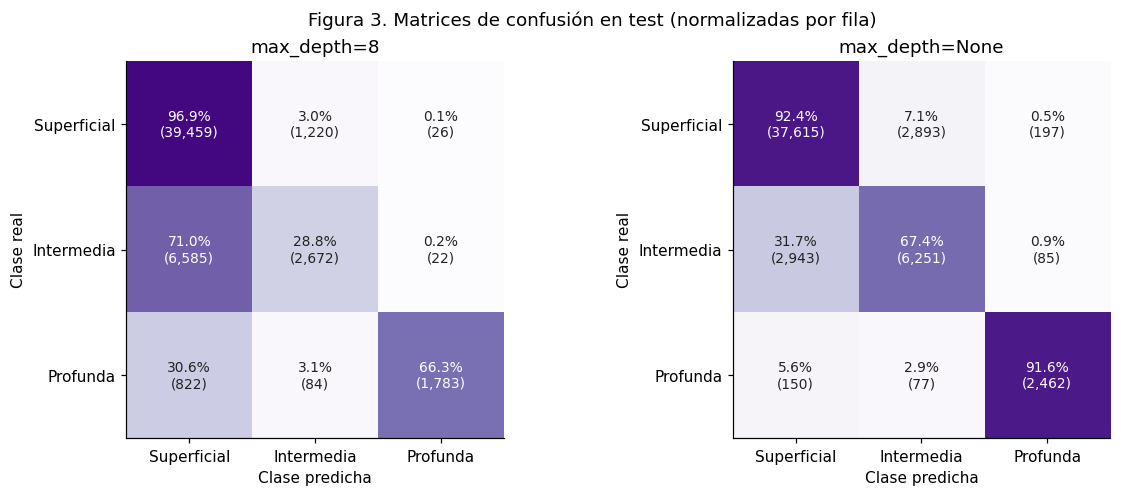

In [ ]:
cm_base = confusion_matrix(y_test, pred_test_base, labels=CLASES)
cm_libre = confusion_matrix(y_test, pred_test_libre, labels=CLASES)

fig, axs = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
for ax, cm, nombre in zip(axs, [cm_base, cm_libre], ['max_depth=8', 'max_depth=None']):
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cm_norm, cmap='Purples', vmin=0, vmax=1)
    ax.set_xticks(range(3), CLASES)
    ax.set_yticks(range(3), CLASES)
    ax.set(xlabel='Clase predicha', ylabel='Clase real', title=nombre)
    ax.grid(False)
    for i in range(3):
        for j in range(3):
            p = cm_norm[i, j]
            ax.text(j, i, f'{p:.1%}\n({cm[i, j]:,})', ha='center', va='center',
                    color='white' if p > .55 else '#222222', fontsize=9)
fig.suptitle('Figura 3. Matrices de confusión en test (normalizadas por fila)')
plt.show()

Como usamos latitud y longitud, también nos interesa saber en qué lugares se concentran los errores. En la Figura 4 aparecen todos los eventos de test en gris y, sobre ellos, los que cada árbol clasificó mal. El color indica la categoría real del terremoto.


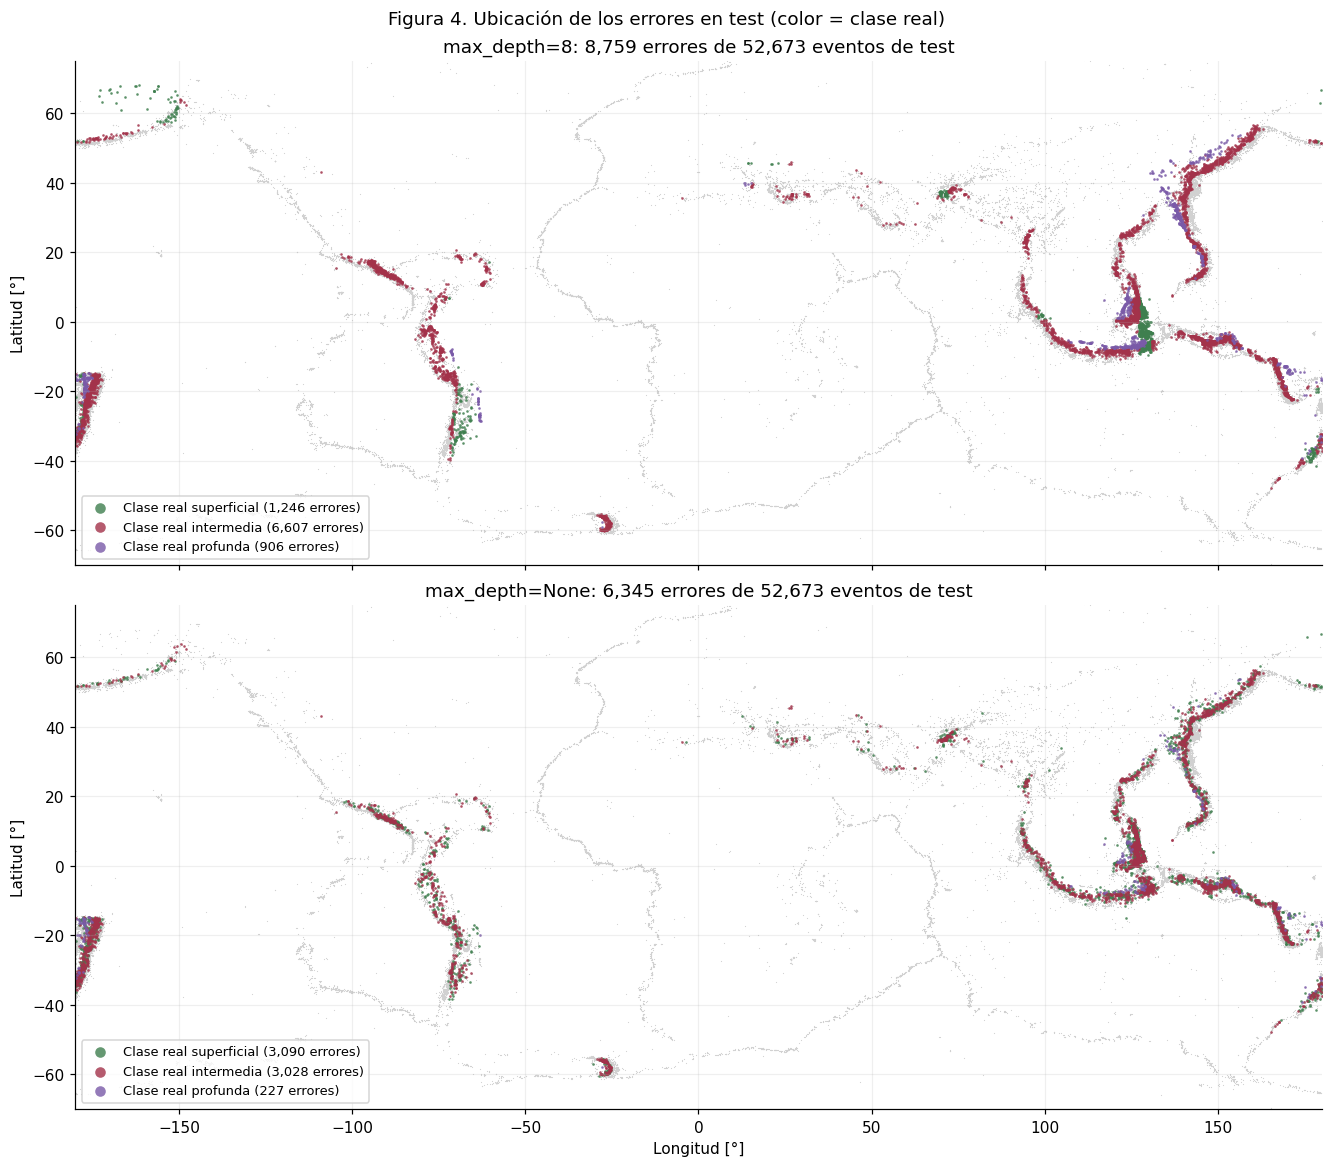

In [ ]:
auditoria = X_test.copy()
auditoria['depth'] = base.loc[X_test.index, 'depth']
auditoria['place'] = base.loc[X_test.index, 'place']
auditoria['real'] = y_test
auditoria['pred_8'] = pred_test_base
auditoria['pred_libre'] = pred_test_libre
auditoria['error_8'] = auditoria['real'] != auditoria['pred_8']
auditoria['error_libre'] = auditoria['real'] != auditoria['pred_libre']

fig, axs = plt.subplots(2, 1, figsize=(12, 10.5), sharex=True, constrained_layout=True)
for ax, col, nombre in zip(axs, ['error_8', 'error_libre'], ['max_depth=8', 'max_depth=None']):
    ax.scatter(auditoria['longitude'], auditoria['latitude'], s=0.6, color='0.82', lw=0)
    for clase in CLASES:
        e = auditoria[auditoria[col] & auditoria['real'].eq(clase)]
        ax.scatter(e['longitude'], e['latitude'], s=3, color=COLOR[clase], lw=0, alpha=.8,
                   label=f'Clase real {clase.lower()} ({len(e):,} errores)')
    ax.set(xlim=(-180, 180), ylim=(-70, 75), ylabel='Latitud [°]',
           title=f'{nombre}: {auditoria[col].sum():,} errores de {len(auditoria):,} eventos de test')
    ax.legend(loc='lower left', markerscale=4, fontsize=8.5, frameon=True)
axs[1].set_xlabel('Longitud [°]')
fig.suptitle('Figura 4. Ubicación de los errores en test (color = clase real)')
plt.show()

Para ver errores concretos, elegimos algunos sismos profundos clasificados como superficiales, intermedios clasificados como superficiales y superficiales clasificados como profundos. Incluimos `place` para reconocer en qué región ocurrieron, pero esta columna no se utilizó para entrenar.


In [ ]:
cols = ['place', 'latitude', 'longitude', 'mag', 'depth', 'real', 'pred_8', 'pred_libre']
ejemplos = pd.concat([
    auditoria[auditoria['real'].eq('Profunda') & auditoria['pred_8'].eq('Superficial')]
        .sort_values('depth', ascending=False).head(4),
    auditoria[auditoria['real'].eq('Intermedia') & auditoria['pred_8'].eq('Superficial')]
        .sort_values('depth', ascending=False).head(3),
    auditoria[auditoria['real'].eq('Superficial') & auditoria['pred_8'].eq('Profunda')]
        .sort_values('depth').head(3)])
with pd.option_context('display.max_colwidth', 40, 'display.width', 200):
    display(ejemplos[cols].round({'latitude': 2, 'longitude': 2, 'depth': 1}))

# Verificación cuantitativa de la observación sobre los valores exactos 10 y 33 km.
casos_sup_prof = auditoria[auditoria['real'].eq('Superficial') & auditoria['pred_8'].eq('Profunda')]
casos_10_33 = casos_sup_prof['depth'].isin([10, 33]).sum()
print(f'De los {len(casos_sup_prof)} superficiales predichos como profundos, '
      f'{casos_10_33} tienen profundidad reportada exactamente en 10 o 33 km.')


,place,latitude,longitude,mag,depth,real,pred_8,pred_libre
227054,"Bonin Islands, Japan region",27.88,140.58,4.9,677.6,Profunda,Superficial,Superficial
121763,"273 km SSE of Manuk Mangkaw, Philipp...",2.56,120.90,4.8,675.1,Profunda,Superficial,Profunda
58150,"235 km ENE of Sola, Vanuatu",-12.84,169.45,4.8,668.6,Profunda,Superficial,Profunda
257062,"68 km ENE of Ranau, Malaysia",6.29,117.18,4.5,667.4,Profunda,Superficial,Superficial
138013,south of the Fiji Islands,-24.72,-177.49,4.5,300.0,Intermedia,Superficial,Intermedia
72941,Mariana Islands region,21.76,142.96,4.5,300.0,Intermedia,Superficial,Intermedia
130525,"211 km NW of Nuku‘alofa, Tonga",-19.60,-176.41,4.7,300.0,Intermedia,Superficial,Superficial
257006,"102 km SSE of Alo, Wallis and Futuna",-15.16,-177.74,4.6,10.0,Superficial,Profunda,Profunda
283598,"205 km SSE of Suva, Fiji",-19.95,178.87,4.7,10.0,Superficial,Profunda,Profunda
173450,"132 km SSE of Suva, Fiji",-19.28,178.85,4.7,10.0,Superficial,Profunda,Profunda


De los 26 superficiales predichos como profundos, 18 tienen profundidad reportada exactamente en 10 o 33 km.


Buscamos si los errores tienen algo en común. Para eso analizamos dos aspectos, solo después de evaluar los modelos:

1. Profundidad real: agrupamos los eventos de test en franjas para ver si los errores aumentan cerca de los límites entre categorías.
2. Entorno del epicentro: buscamos sismos de entrenamiento a menos de 25 km de cada evento de test. Si en ese entorno hay más de una clase, lo llamamos zona mixta. Esto nos ayuda a estudiar si la ubicación puede resultar ambigua.

Las etiquetas reales del test se usan para estudiar los errores, no para construir las zonas ni para entrenar.


In [ ]:
d = auditoria['depth']
auditoria['franja'] = np.select(
    [d < 40, d < 70, d < 100, d < 200, d <= 300, d < 400],
    ['0–40', '40–70', '70–100', '100–200', '200–300', '300–400'], default='≥ 400')
orden = ['0–40', '40–70', '70–100', '100–200', '200–300', '300–400', '≥ 400']
tabla_franjas = (auditoria.groupby('franja')
                 .agg(Eventos=('real', 'size'), Clase=('real', 'first'),
                      **{'% error (max_depth=8)': ('error_8', 'mean'),
                         '% error (sin límite)': ('error_libre', 'mean')})
                 .reindex(orden))
tabla_franjas.iloc[:, 2:] *= 100
tabla_franjas.index.name = 'Profundidad real [km]'
display(tabla_franjas.round(1))

,Eventos,Clase,% error (max_depth=8),% error (sin límite)
Profundidad real [km],,,,
0–40,34226,Superficial,2.8,6.0
40–70,6479,Superficial,4.2,15.9
70–100,2802,Intermedia,87.1,54.2
100–200,5344,Intermedia,64.5,23.2
200–300,1133,Intermedia,63.5,23.7
300–400,377,Profunda,79.8,30.0
≥ 400,2312,Profunda,26.2,4.9


In [ ]:
# Exploración descriptiva: radio de 25 km elegido para esta auditoría; no es un umbral físico universal.
# Solo consultamos el entorno de entrenamiento, sin usar las etiquetas de test para definir las zonas.
R_TIERRA, RADIO = 6371.0, 25.0
arbol_bt = BallTree(np.radians(X_train[['latitude', 'longitude']].values), metric='haversine')
vecinos = arbol_bt.query_radius(np.radians(X_test[['latitude', 'longitude']].values), r=RADIO / R_TIERRA)
clases_train = y_train.to_numpy()
n_clases = np.array([len(set(clases_train[v])) for v in vecinos])
auditoria['zona'] = np.select([n_clases == 0, n_clases == 1],
                              ['Sin vecinos a < 25 km', 'Zona pura (1 clase)'],
                              default='Zona mixta (2–3 clases)')

dist, _ = arbol_bt.query(np.radians(X_test[['latitude', 'longitude']].values), k=1)
print(f'Mediana de la distancia al evento de entrenamiento más cercano: {np.median(dist) * R_TIERRA:.1f} km')

orden_zonas = ['Zona pura (1 clase)', 'Zona mixta (2–3 clases)', 'Sin vecinos a < 25 km']
g = auditoria.groupby('zona')
tabla_zonas = pd.DataFrame({
    '% de los eventos de test': 100 * g.size() / len(auditoria),
    '% error (max_depth=8)': 100 * g['error_8'].mean(),
    '% error (sin límite)': 100 * g['error_libre'].mean(),
    '% de todos los errores (max_depth=8)': 100 * g['error_8'].sum() / auditoria['error_8'].sum(),
    '% de todos los errores (sin límite)': 100 * g['error_libre'].sum() / auditoria['error_libre'].sum(),
}).reindex(orden_zonas)
display(tabla_zonas.round(1))

Mediana de la distancia al evento de entrenamiento más cercano: 3.2 km


,% de los eventos de test,% error (max_depth=8),% error (sin límite),% de todos los errores (max_depth=8),% de todos los errores (sin límite)
zona,,,,,
Zona pura (1 clase),49.0,5.4,2.3,15.9,9.4
Zona mixta (2–3 clases),47.9,28.7,22.3,82.6,88.7
Sin vecinos a < 25 km,3.1,7.7,7.6,1.4,2.0


### Interpretación de los errores

1. No todas las clases presentan las mismas dificultades. Con el árbol de ocho niveles, 6.585 de los 9.279 sismos intermedios del test se clasificaron como superficiales, ese es el error más común. El árbol sin límite reduce esa cantidad a 2.942, pero a cambio confunde más eventos superficiales con intermedios. Por eso el recall superficial baja de 96,9% a 92,4%. Mejorar una clase no garantiza mejorar todas.

2. La ubicación y los límites entre categorías importan. En el mapa vemos que muchos errores aparecen en regiones de subducción, como los márgenes de Sudamérica y el Pacífico occidental. También hay dificultades cerca de los cortes de profundidad ya que el árbol original se equivoca en el 87,1% de los sismos entre 70 y 100 km y en el 79,8% de los que están entre 300 y 400 km. Con el árbol sin límite esas tasas bajan a 54,0% y 29,4%. Esto sugiere que los cortes influyen, aunque no explican todos los errores.

3. Las zonas mixtas reúnen buena parte de los errores. Definimos una zona mixta como un entorno de 25 km donde hay sismos de entrenamiento de distintas categorías. Estas zonas incluyen el 47,9% de los eventos de test, pero concentran el 82,6% de los errores del árbol original y el 88,8% de los del árbol sin límite. La tasa de error en esas zonas es de 28,7% y 22,3%, respectivamente, frente a 5,4% y 2,3% en los entornos donde solo se observó una categoría. Una explicación posible es la geometría de las zonas de subducción debido a que dos sismos pueden tener epicentros cercanos y profundidades muy diferentes. Los resultados son compatibles con esta idea, pero no demuestran que sea la única causa. Además elegimos los 25 km como criterio exploratorio, no porque exista un límite físico universal, si cambiamos el radio los porcentajes también podrían cambiar.

4. De los 26 sismos superficiales que el árbol original clasificó como profundos, 18 tienen profundidades exactamente de 10 o 33 km. Son valores que en ciertos registros se han utilizado de manera convencional, pero no podemos afirmar que esos 18 casos estén mal medidos solo por aparecer con esos números. En total, el 41,9% de la muestra presenta una de esas dos profundidades.

En resumen, el desempeño depende de la categoría que intentamos predecir y del lugar del terremoto. Un árbol más complejo reduce varios errores, pero sigue teniendo dificultades cuando distintas profundidades aparecen en zonas cercanas.


### 6.3 ¿Qué aprendimos que no se veía con una única métrica?

También revisamos la importancia de las variables. En un árbol, esta medida resume cuánto contribuyen las divisiones de cada variable a reducir la impureza de Gini. Las importancias se normalizan para que sumen 1, no representan una relación causal.


In [ ]:
importancias = pd.DataFrame({'max_depth=8': arbol_base.feature_importances_,
                             'max_depth=None': arbol_libre.feature_importances_},
                            index=FEATURES).round(3)
display(importancias)

,max_depth=8,max_depth=None
latitude,0.422,0.444
longitude,0.576,0.507
mag,0.002,0.049


El accuracy del árbol original es de 83,4%, lo que a primera vista parece un buen resultado, pero al mirar cada categoría encontramos que solo identifica correctamente el 28,8% de los sismos intermedios. Esa diferencia explica por qué necesitábamos el F1-macro, el recall por clase y las matrices de confusión.

También vimos que un árbol que sobreajusta puede rendir mejor en test que otro que subajusta. Al quitar el límite de profundidad, el F1-macro de test subió de 0,698 a 0,836, aunque aumentó la diferencia con entrenamiento.

En cuanto a las variables, el árbol original da una importancia de 0,422 a `latitude`, 0,576 a `longitude` y apenas 0,002 a `mag`. En el árbol sin límite, la importancia de `mag` sube a 0,049. Es decir, el primer árbol casi no utiliza la magnitud para tomar decisiones. Esto no significa que la magnitud no contenga información: para saber qué pasa al quitarla habría que hacer otra prueba, y aquí solo modificamos un aspecto del modelo.

Finalmente, el mapa y las zonas mixtas muestran que el lugar donde ocurre el sismo influye en los errores, algo que no se aprecia al mirar un único número.

### 6.4 ¿Cómo mejoraríamos el modelo?

Proponemos elegir mejor la complejidad del árbol mediante validación cruzada estratificada, utilizando solo los datos de entrenamiento. Por ejemplo, podríamos comparar unos pocos valores de `max_depth` o de `min_samples_leaf` (cantidad mínima de ejemplos por hoja) con cinco particiones. Después evaluaríamos una sola vez el modelo elegido en el test reservado.

La propuesta surge de lo que observamos: ocho niveles parecen insuficientes, mientras que dejar crecer el árbol sin límite hace que memorice el entrenamiento. Buscar un punto intermedio podría permitirnos conservar los patrones útiles sin aprender tantos detalles particulares. No sabemos si mejoraría el resultado, habría que comprobarlo.

Además, como hay sismos muy cercanos entre sí, una validación aleatoria puede dar resultados optimistas. Más adelante sería interesante evaluar el modelo en períodos o regiones distintos de los usados para entrenar.


## 7. Conclusiones

Con las variables que elegimos, sí es posible aprender patrones útiles para clasificar la profundidad de terremotos ya registrados. El árbol de ocho niveles obtuvo un F1-macro de 0,698 en test, pero identificó correctamente solo el 28,8% de los sismos intermedios. Al quitar el límite de profundidad, el F1-macro subió a 0,836, junto con el recall de intermedios (67,4%) y profundos (91,5%). Sin embargo, el árbol más complejo también mostró sobreajuste, porque alcanzó 1,000 en entrenamiento.

La principal fortaleza del modelo es que aprovecha la información geográfica y supera la referencia de predecir siempre superficial (F1-macro 0,291). Su limitación más clara aparece en zonas donde hay sismos de distintas profundidades con epicentros cercanos. Con el radio exploratorio de 25 km, esas zonas reúnen el 88,8% de los errores del árbol sin límite, aunque representan el 47,9% del test. También debemos considerar la incertidumbre de algunas profundidades del catálogo.

Por eso, vemos el modelo como una herramienta exploratoria, no como una forma confiable de clasificar cualquier terremoto nuevo. Nuestra evaluación se hizo con una división aleatoria y no sabemos si el rendimiento se mantendría en otras regiones o períodos. Para mejorar el trabajo, intentaríamos controlar la complejidad del árbol con validación cruzada usando únicamente el entrenamiento.


## Referencias y uso de herramientas de IA

- **Datos:** catálogo `earthquakes_usgs.csv` (USGS), entregado en Moodle y utilizado en la Tarea 1.
- **Herramientas de análisis:** Python, pandas, NumPy, Matplotlib y scikit-learn (`train_test_split`, `DecisionTreeClassifier`, `BallTree` y métricas de clasificación).
- **Contexto sismológico:** [USGS — Determining the Depth of an Earthquake](https://www.usgs.gov/programs/earthquake-hazards/determining-depth-earthquake) y [USGS — Why do so many earthquakes occur at a depth of 10 km?](https://www.usgs.gov/faqs/why-do-so-many-earthquakes-occur-a-depth-10km). Se consultaron para contextualizar posibles profundidades fijadas, no para determinar cuáles registros del archivo tienen esa condición.
- **Uso de IA:** Los códigos fueron generados con inteligencia artificial, para luego analizar sus resultados.
